# Real-data path-specific mitigation

In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').exists())
sys.path.insert(0, str(REPO_ROOT / 'src')) if str(REPO_ROOT / 'src') not in sys.path else None

from data_preparation import (make_compas_workflow_data, make_law_school_workflow_data,
    make_reddit_workflow_data, make_scut_workflow_data, prepare_compas,
    prepare_law_school, prepare_reddit, prepare_scut,
    reduce_external_workflow_data)
from mitigation import (effect_results_frame, mitigation_specifications, overlap_summary,
    mitigation_compact_overview_table, mitigation_overview_table,
    plot_mitigation_summary_figure,
    plot_strategy_effects, run_mitigation_analysis)

RANDOM_STATE = 9
SPLIT_RANDOM_STATE = 2026
PENALTY_STRENGTH = 200
EMBEDDING_PENALTY_STRENGTH = 10
REDDIT_SAMPLE_SIZE = None  
DR_OPTIONS = dict(n_splits= 5, random_state=RANDOM_STATE, propensity_clip=.01)
MODEL_OPTIONS = dict(n_splits=5, random_state=RANDOM_STATE, l2=1e-5, max_iter=1000)


/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Law School

In [2]:
law_path = REPO_ROOT / 'data' / 'law_school' / 'bar_pass_prediction.csv'
law_dataset = prepare_law_school(law_path)
law = make_law_school_workflow_data(
    law_dataset, test_size=.30, random_state=SPLIT_RANDOM_STATE,
)["mitigation"]

display(pd.Series(law_dataset['provenance']['cohort_audit']['counts'], name='n').to_frame())
display(pd.DataFrame({
    'partition': ['train', 'test'],
    'n': [len(law['train']), len(law['test'])],
    'non_white_fraction': [law['train']['A'].mean(), law['test']['A'].mean()],
    'outcome_rate': [law['train']['Y'].mean(), law['test']['Y'].mean()],
}).round(4))

,n
source_rows,22407
after_observed_race,22391
after_binary_bar_outcome,22391
complete_case_rows,20970


,partition,n,non_white_fraction,outcome_rate
0,train,14679,0.1628,0.9490
1,test,6291,0.1628,0.9491


In [3]:
law_direct, law_indirect = mitigation_specifications('White', 'Non-White')
law_result = run_mitigation_analysis(
    law['train'], law['test'],
    outcome=law['outcome'], protected_attribute=law['protected_attribute'],
    mediators=law['mediators'], confounders=law['confounders'],
    direct_specifications=law_direct, indirect_specifications=law_indirect,
    outcome_type='binary', penalty_strength=PENALTY_STRENGTH,
    estimator_kwargs=DR_OPTIONS, **MODEL_OPTIONS,
)

,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nde_m0,-0.0155,0.0017,-0.0188,-0.0122
1,No mitigation,nde_m1,-0.0291,0.0018,-0.0325,-0.0256
2,NDE at White M(0),nde_m0,-0.0003,0.0007,-0.0016,0.0010
3,NDE at White M(0),nde_m1,-0.0087,0.0017,-0.0121,-0.0053
4,NDE at Non-White M(1),nde_m0,-0.0102,0.0010,-0.0121,-0.0082
5,NDE at Non-White M(1),nde_m1,-0.0089,0.0015,-0.0119,-0.0058
6,Symmetric NDE,nde_m0,-0.0066,0.0008,-0.0081,-0.0050
7,Symmetric NDE,nde_m1,-0.0037,0.0015,-0.0067,-0.0007
8,Both NDEs,nde_m0,-0.0007,0.0005,-0.0017,0.0003
9,Both NDEs,nde_m1,-0.0032,0.0016,-0.0063,-0.0001


,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nie_a0,-0.0804,0.0043,-0.0889,-0.0720
1,No mitigation,nie_a1,-0.0940,0.0049,-0.1036,-0.0844
2,NIE while White,nie_a0,-0.0077,0.0021,-0.0119,-0.0035
3,NIE while White,nie_a1,-0.0919,0.0053,-0.1023,-0.0814
4,NIE while Non-White,nie_a0,-0.0669,0.0034,-0.0736,-0.0601
5,NIE while Non-White,nie_a1,0.0075,0.0041,-0.0004,0.0155
6,Symmetric NIE,nie_a0,-0.0241,0.0019,-0.0278,-0.0205
7,Symmetric NIE,nie_a1,0.0343,0.0051,0.0243,0.0442
8,Both NIEs,nie_a0,-0.0031,0.0016,-0.0062,0.0001
9,Both NIEs,nie_a1,0.0063,0.0048,-0.0031,0.0156


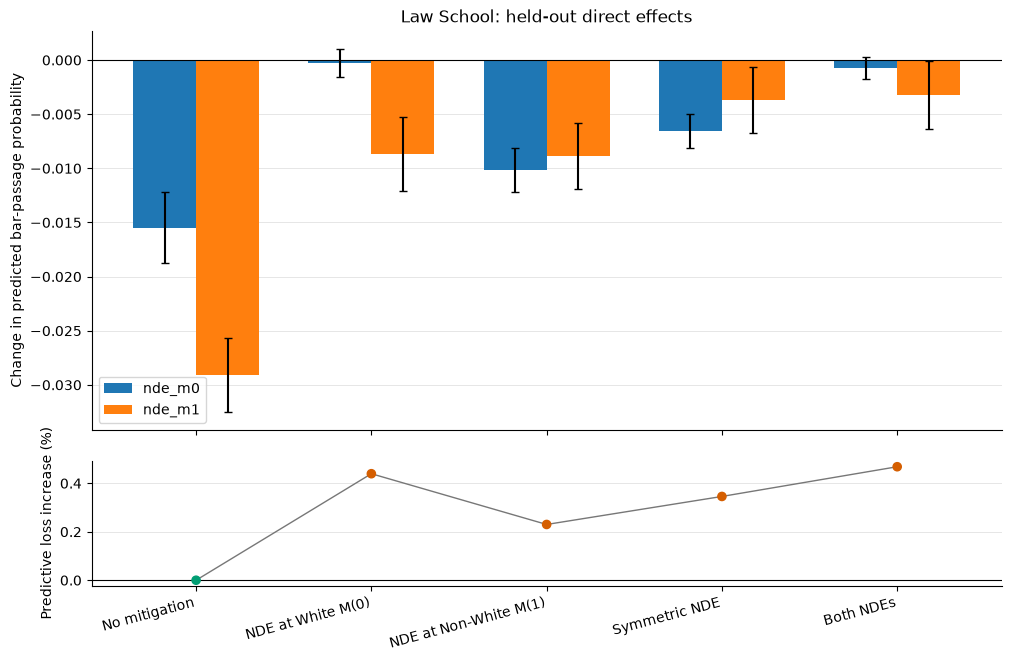

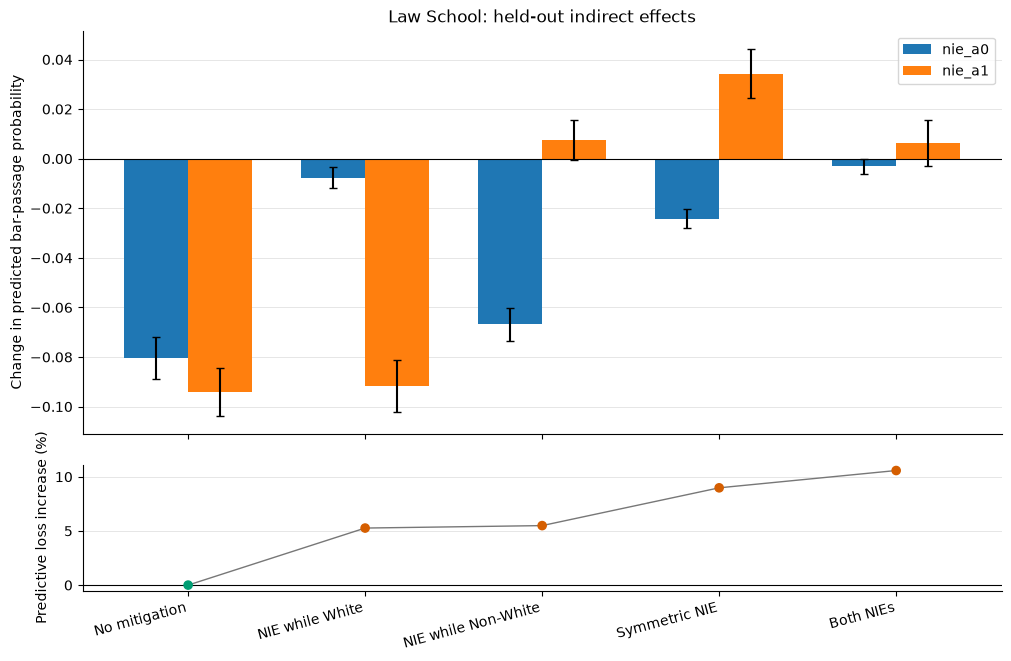

In [4]:
law_direct_effects = effect_results_frame(law_result['direct'], ('nde_m0', 'nde_m1'))
law_indirect_effects = effect_results_frame(law_result['indirect'], ('nie_a0', 'nie_a1'))
display(law_direct_effects.round(4))
display(law_indirect_effects.round(4))

plot_strategy_effects(
    law_result['direct'], ('nde_m0', 'nde_m1'),
    law_result['performance'], metric='log_loss',
    title='Law School: held-out direct effects',
    ylabel='Change in predicted bar-passage probability',
)
plt.show()
plot_strategy_effects(
    law_result['indirect'], ('nie_a0', 'nie_a1'),
    law_result['performance'], metric='log_loss',
    title='Law School: held-out indirect effects',
    ylabel='Change in predicted bar-passage probability',
)
plt.show()

In [5]:
display(law_result['performance'].set_index(['strategy', 'scope']).round(4))
display(overlap_summary(law_result['held_out_evaluations']).set_index('strategy').round(4))
optimization = pd.DataFrame({
    strategy: fitted['optimization']
    for strategy, fitted in law_result['models'].items()
}).T
display(optimization[['converged', 'prediction_loss', 'objective', 'message']])

n  accuracy   auroc  log_loss
strategy              scope                                    
No mitigation         overall  6291    0.9504  0.8599    0.1517
                      A=0      5267    0.9681  0.8322    0.1173
                      A=1      1024    0.8594  0.8120    0.3288
NDE at White M(0)     overall  6291    0.9501  0.8586    0.1524
                      A=0      5267    0.9681  0.8323    0.1174
                      A=1      1024    0.8574  0.8100    0.3324
NDE at Non-White M(1) overall  6291    0.9507  0.8593    0.1521
                      A=0      5267    0.9683  0.8323    0.1176
                      A=1      1024    0.8604  0.8121    0.3293
Symmetric NDE         overall  6291    0.9504  0.8590    0.1523
                      A=0      5267    0.9683  0.8323    0.1177
                      A=1      1024    0.8584  0.8116    0.3302
Both NDEs             overall  6291    0.9506  0.8586    0.1524
                      A=0      5267    0.9683  0.8325    0.1175
                      A=1      1024    0.8594  0.8103    0.3322
NIE while White       overall  6291    0.9499  0.8269    0.1597
                      A=0      5267    0.9672  0.7678    0.1267
                      A=1      1024    0.8613  0.8104    0.3298
NIE while Non-White   overall  6291    0.9499  0.8375    0.1601
                      A=0      5267    0.9681  0.8317    0.1174
                      A=1      1024    0.8564  0.7043    0.3795
Symmetric NIE         overall  6291    0.9488  0.8221    0.1654
                      A=0      5267    0.9672  0.8160    0.1197
                      A=1      1024    0.8545  0.6363    0.4004
Both NIEs             overall  6291    0.9491  0.8060    0.1678
                      A=0      5267    0.9672  0.7677    0.1266
                      A=1      1024    0.8564  0.7063    0.3794

,max_propensity_c_clipped,max_propensity_mc_clipped,max_absolute_weight,effective_sample_size
strategy,,,,
No mitigation,0.0,0.0315,125.0297,208.3368
NDE at White M(0),0.0,0.0315,125.0297,208.3368
NDE at Non-White M(1),0.0,0.0315,125.0297,208.3368
Symmetric NDE,0.0,0.0315,125.0297,208.3368
Both NDEs,0.0,0.0315,125.0297,208.3368
NIE while White,0.0,0.0315,125.0297,208.3368
NIE while Non-White,0.0,0.0315,125.0297,208.3368
Symmetric NIE,0.0,0.0315,125.0297,208.3368
Both NIEs,0.0,0.0315,125.0297,208.3368


,converged,prediction_loss,objective,message
No mitigation,True,0.151397,0.151418,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
NDE at White M(0),True,0.151871,0.151895,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
NDE at Non-White M(1),True,0.151625,0.151647,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NDE,True,0.15175,0.151772,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Both NDEs,True,0.151897,0.15192,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while White,True,0.161538,0.161903,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
NIE while Non-White,True,0.160585,0.160681,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NIE,True,0.166817,0.166987,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Both NIEs,True,0.170475,0.170881,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## COMPAS

In [6]:
compas_path = REPO_ROOT / 'data' / 'compas' / 'cox-violent-parsed.csv'
compas_dataset = prepare_compas(compas_path)
compas = make_compas_workflow_data(
    compas_dataset, test_size=.30, random_state=SPLIT_RANDOM_STATE,
)["mitigation"]

display(pd.Series(compas_dataset['provenance']['cohort_audit']['counts'], name='n').to_frame())
display(pd.DataFrame({
    'partition': ['train', 'test'],
    'n': [len(compas['train']), len(compas['test'])],
    'female_fraction': [compas['train']['A'].mean(), compas['test']['A'].mean()],
    'recidivism_rate': [compas['train']['Y'].mean(), compas['test']['Y'].mean()],
}).round(4))

,n
source_rows,18316
after_screening_window,14802
after_valid_recidivism,14801
after_valid_charge_degree,14801
after_available_score,14801
after_unique_person,8900
after_binary_recorded_sex,8900
complete_case_rows,8899


,partition,n,female_fraction,recidivism_rate
0,train,6229,0.1785,0.4860
1,test,2670,0.1787,0.4861


In [7]:
compas_direct, compas_indirect = mitigation_specifications('Male', 'Female')
compas_result = run_mitigation_analysis(
    compas['train'], compas['test'],
    outcome=compas['outcome'], protected_attribute=compas['protected_attribute'],
    mediators=compas['mediators'], confounders=compas['confounders'],
    direct_specifications=compas_direct, indirect_specifications=compas_indirect,
    outcome_type='binary', penalty_strength=PENALTY_STRENGTH,
    estimator_kwargs=DR_OPTIONS, **MODEL_OPTIONS,
)

,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nde_m0,-0.1085,0.0067,-0.1217,-0.0954
1,No mitigation,nde_m1,-0.1295,0.0028,-0.1351,-0.1239
2,NDE at Male M(0),nde_m0,0.0040,0.0083,-0.0123,0.0202
3,NDE at Male M(0),nde_m1,-0.0279,0.0035,-0.0347,-0.0211
4,NDE at Female M(1),nde_m0,0.0083,0.0051,-0.0016,0.0182
5,NDE at Female M(1),nde_m1,-0.0016,0.0028,-0.0072,0.0039
6,Symmetric NDE,nde_m0,0.0118,0.0074,-0.0027,0.0263
7,Symmetric NDE,nde_m1,-0.0113,0.0031,-0.0174,-0.0051
8,Both NDEs,nde_m0,0.0035,0.0042,-0.0047,0.0117
9,Both NDEs,nde_m1,-0.0010,0.0028,-0.0065,0.0045


,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nie_a0,-0.0531,0.0066,-0.0661,-0.0401
1,No mitigation,nie_a1,-0.0741,0.0094,-0.0925,-0.0557
2,NIE while Male,nie_a0,-0.0101,0.0039,-0.0178,-0.0024
3,NIE while Male,nie_a1,-0.0773,0.0112,-0.0992,-0.0553
4,NIE while Female,nie_a0,-0.0519,0.0066,-0.0648,-0.0390
5,NIE while Female,nie_a1,-0.0035,0.0056,-0.0145,0.0075
6,Symmetric NIE,nie_a0,-0.0369,0.0054,-0.0474,-0.0264
7,Symmetric NIE,nie_a1,0.0314,0.0077,0.0163,0.0464
8,Both NIEs,nie_a0,-0.0111,0.0038,-0.0186,-0.0036
9,Both NIEs,nie_a1,-0.0080,0.0048,-0.0174,0.0015


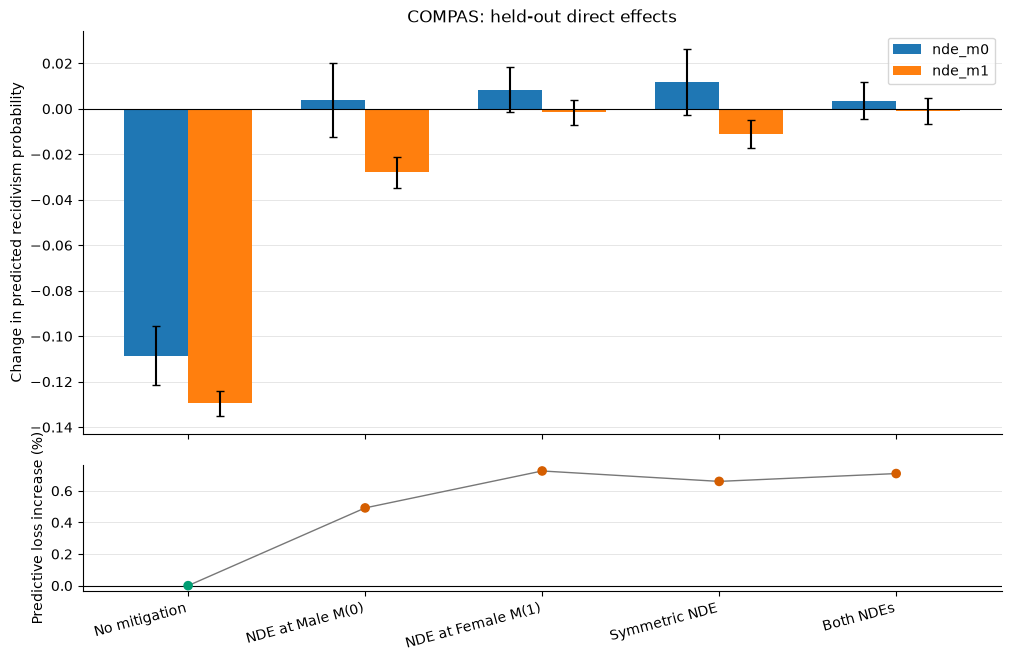

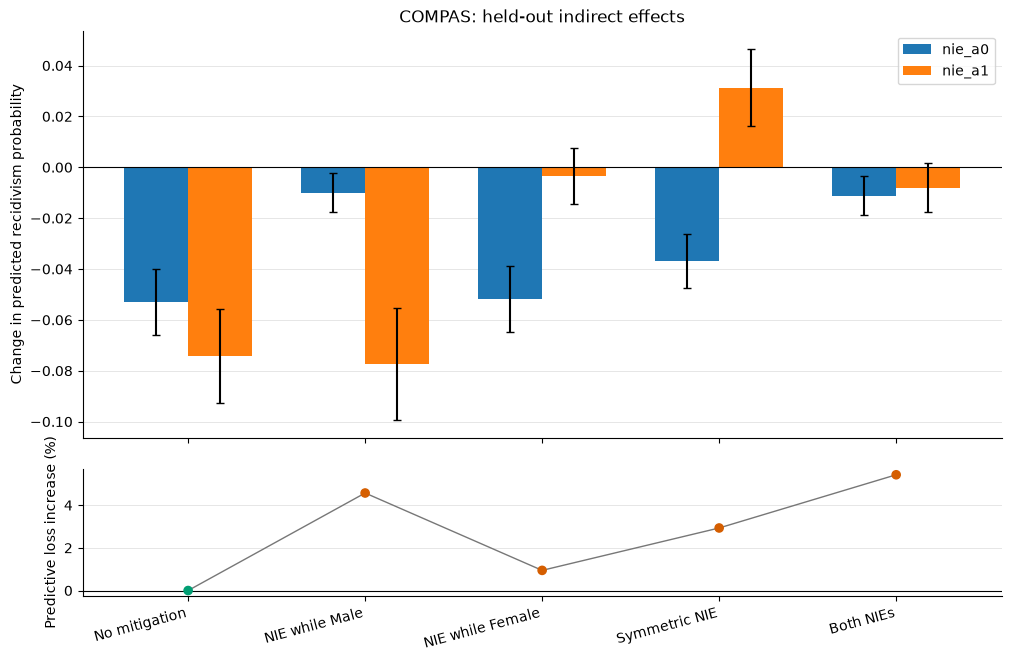

In [8]:
compas_direct_effects = effect_results_frame(compas_result['direct'], ('nde_m0', 'nde_m1'))
compas_indirect_effects = effect_results_frame(compas_result['indirect'], ('nie_a0', 'nie_a1'))
display(compas_direct_effects.round(4))
display(compas_indirect_effects.round(4))

plot_strategy_effects(
    compas_result['direct'], ('nde_m0', 'nde_m1'),
    compas_result['performance'], metric='log_loss',
    title='COMPAS: held-out direct effects',
    ylabel='Change in predicted recidivism probability',
)
plt.show()
plot_strategy_effects(
    compas_result['indirect'], ('nie_a0', 'nie_a1'),
    compas_result['performance'], metric='log_loss',
    title='COMPAS: held-out indirect effects',
    ylabel='Change in predicted recidivism probability',
)
plt.show()

In [9]:
display(compas_result['performance'].set_index(['strategy', 'scope']).round(4))
display(overlap_summary(compas_result['held_out_evaluations']).set_index('strategy').round(4))
compas_optimization = pd.DataFrame({
    strategy: fitted['optimization']
    for strategy, fitted in compas_result['models'].items()
}).T
display(compas_optimization[['converged', 'prediction_loss', 'objective', 'message']])

n  accuracy   auroc  log_loss
strategy           scope                                    
No mitigation      overall  2670    0.6652  0.7225    0.6153
                   A=0      2193    0.6626  0.7210    0.6180
                   A=1       477    0.6771  0.6660    0.6028
NDE at Male M(0)   overall  2670    0.6678  0.7208    0.6183
                   A=0      2193    0.6653  0.7216    0.6181
                   A=1       477    0.6792  0.6713    0.6193
NDE at Female M(1) overall  2670    0.6625  0.7170    0.6198
                   A=0      2193    0.6630  0.7218    0.6182
                   A=1       477    0.6604  0.6611    0.6268
Symmetric NDE      overall  2670    0.6648  0.7189    0.6194
                   A=0      2193    0.6662  0.7217    0.6185
                   A=1       477    0.6583  0.6677    0.6235
Both NDEs          overall  2670    0.6614  0.7166    0.6197
                   A=0      2193    0.6630  0.7220    0.6180
                   A=1       477    0.6541  0.6579    0.6272
NIE while Male     overall  2670    0.6390  0.6894    0.6434
                   A=0      2193    0.6275  0.6783    0.6525
                   A=1       477    0.6918  0.6644    0.6016
NIE while Female   overall  2670    0.6614  0.7147    0.6211
                   A=0      2193    0.6639  0.7204    0.6184
                   A=1       477    0.6499  0.5950    0.6334
Symmetric NIE      overall  2670    0.6483  0.7024    0.6334
                   A=0      2193    0.6534  0.7165    0.6251
                   A=1       477    0.6247  0.5127    0.6714
Both NIEs          overall  2670    0.6348  0.6818    0.6487
                   A=0      2193    0.6279  0.6782    0.6527
                   A=1       477    0.6667  0.5976    0.6305

,max_propensity_c_clipped,max_propensity_mc_clipped,max_absolute_weight,effective_sample_size
strategy,,,,
No mitigation,0.0,0.0067,95.53,219.6075
NDE at Male M(0),0.0,0.0067,95.53,219.6075
NDE at Female M(1),0.0,0.0067,95.53,219.6075
Symmetric NDE,0.0,0.0067,95.53,219.6075
Both NDEs,0.0,0.0067,95.53,219.6075
NIE while Male,0.0,0.0067,95.53,219.6075
NIE while Female,0.0,0.0067,95.53,219.6075
Symmetric NIE,0.0,0.0067,95.53,219.6075
Both NIEs,0.0,0.0067,95.53,219.6075


,converged,prediction_loss,objective,message
No mitigation,True,0.6225,0.622698,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
NDE at Male M(0),True,0.626674,0.626899,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NDE at Female M(1),True,0.628092,0.628277,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NDE,True,0.627551,0.62776,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Both NDEs,True,0.6281,0.628311,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while Male,True,0.64332,0.645135,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
NIE while Female,True,0.62726,0.627599,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NIE,True,0.636877,0.638009,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Both NIEs,True,0.647936,0.649807,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## SCUT

In [10]:
scut_dataset = prepare_scut(REPO_ROOT / 'data' / 'SCUT-FBP5500_v2')
scut_raw = make_scut_workflow_data(scut_dataset)['mitigation']
scut, scut_pca = reduce_external_workflow_data(
    scut_raw, method='pca', n_components=.70, random_state=RANDOM_STATE,
    output_prefix='embedding_pc',
)

display(pd.Series(scut_dataset['provenance']['cohort_audit'], name='value').to_frame())
display(pd.DataFrame({
    'partition': ['train', 'test'],
    'n': [len(scut['train']), len(scut['test'])],
    'female_fraction': [scut['train']['A'].mean(), scut['test']['A'].mean()],
    'mean_rating': [scut['train']['Y'].mean(), scut['test']['Y'].mean()],
}).round(4))
display(pd.Series(scut_pca['diagnostics'], name='value').to_frame().round(4))

,value
label_rows,5500
official_train_rows,3300
official_test_rows,2200
analysis_rows,5500
embedding_failures,()


,partition,n,female_fraction,mean_rating
0,train,3300,0.5070,2.9888
1,test,2200,0.4895,2.9940


,value
n_input_features,512.0000
n_output_features,137.0000
explained_variance,0.7014


In [11]:
# ArcFace coordinates predict sex strongly.  Regularize P(A | M, C) more
# heavily here to keep the held-out DR density ratios from being dominated
# by a small number of near-separated observations.
scut_dr_options = {
    **DR_OPTIONS,
    'propensity_mc_model': LogisticRegression(C=.01, max_iter=2000),
}
scut_direct, scut_indirect = mitigation_specifications('Male', 'Female')
scut_result = run_mitigation_analysis(
    scut['train'], scut['test'],
    outcome=scut['outcome'], protected_attribute=scut['protected_attribute'],
    mediators=scut['mediators'], confounders=scut['confounders'],
    direct_specifications=scut_direct, indirect_specifications=scut_indirect,
    outcome_type='continuous', penalty_strength=EMBEDDING_PENALTY_STRENGTH,
    estimator_kwargs=scut_dr_options, **MODEL_OPTIONS,
)

,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nde_m0,0.1323,0.0142,0.1045,0.1602
1,No mitigation,nde_m1,0.1003,0.0138,0.0732,0.1274
2,NDE at Male M(0),nde_m0,0.0089,0.0126,-0.0157,0.0336
3,NDE at Male M(0),nde_m1,0.0192,0.0138,-0.0079,0.0462
4,NDE at Female M(1),nde_m0,0.1183,0.0143,0.0903,0.1463
5,NDE at Female M(1),nde_m1,0.0852,0.0138,0.0582,0.1121
6,Symmetric NDE,nde_m0,0.0337,0.0135,0.0073,0.0601
7,Symmetric NDE,nde_m1,-0.0074,0.0149,-0.0366,0.0218
8,Both NDEs,nde_m0,0.0059,0.0130,-0.0197,0.0314
9,Both NDEs,nde_m1,0.0282,0.0136,0.0015,0.0550


,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nie_a0,0.0716,0.0194,0.0335,0.1097
1,No mitigation,nie_a1,0.0395,0.0210,-0.0017,0.0808
2,NIE while Male,nie_a0,0.0241,0.0191,-0.0134,0.0615
3,NIE while Male,nie_a1,0.0281,0.0218,-0.0145,0.0708
4,NIE while Female,nie_a0,0.0722,0.0196,0.0338,0.1106
5,NIE while Female,nie_a1,0.0689,0.0209,0.0280,0.1098
6,Symmetric NIE,nie_a0,0.0722,0.0197,0.0335,0.1109
7,Symmetric NIE,nie_a1,0.0432,0.0214,0.0012,0.0852
8,Both NIEs,nie_a0,0.0348,0.0193,-0.0030,0.0726
9,Both NIEs,nie_a1,0.0677,0.0207,0.0271,0.1083


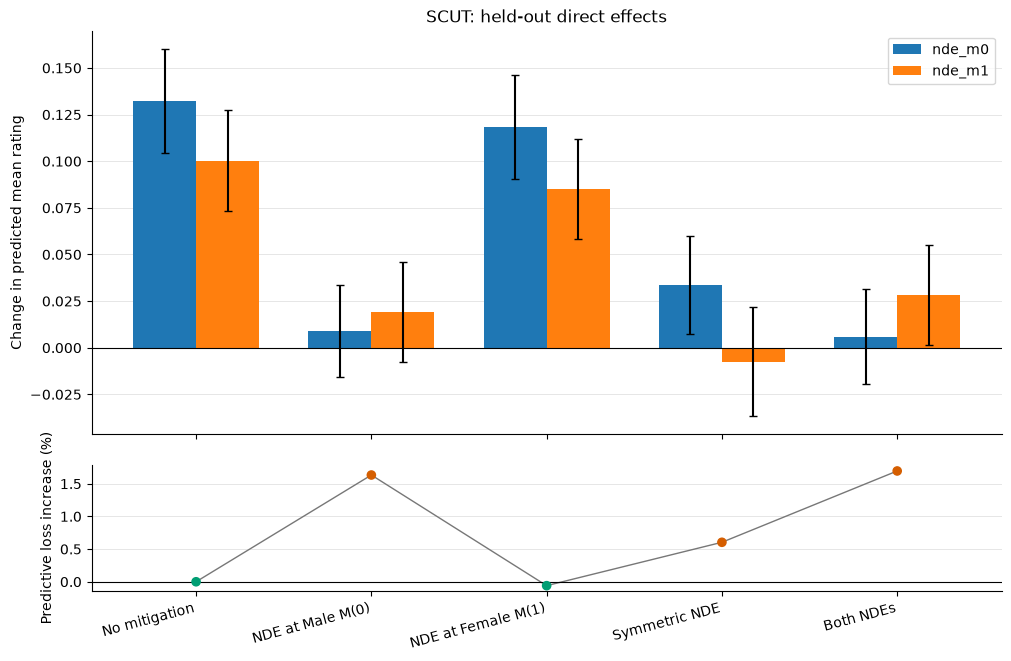

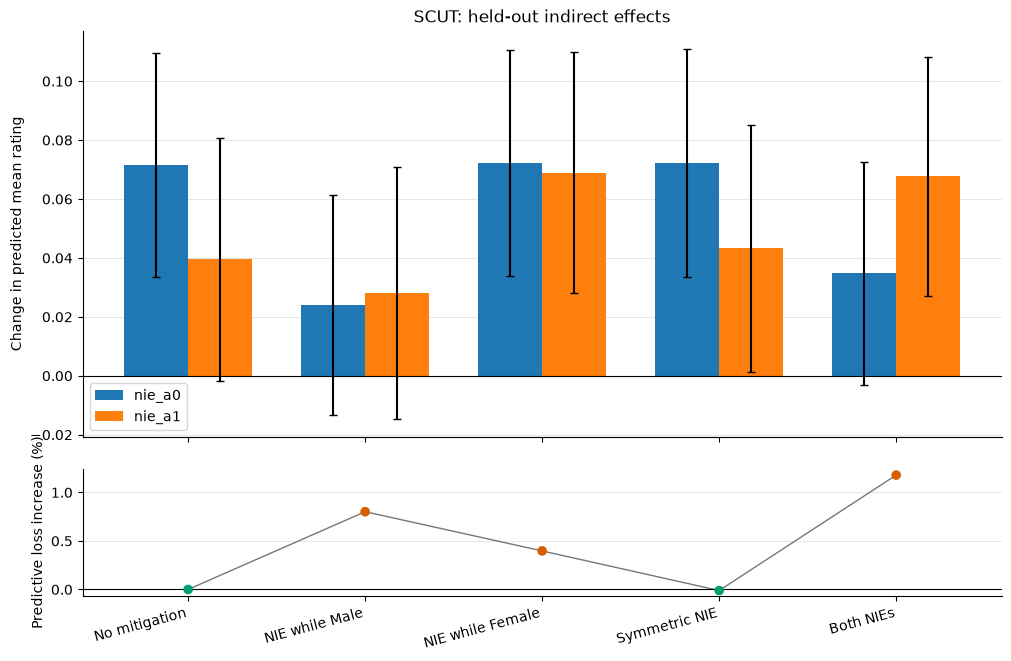

In [12]:
scut_direct_effects = effect_results_frame(scut_result['direct'], ('nde_m0', 'nde_m1'))
scut_indirect_effects = effect_results_frame(scut_result['indirect'], ('nie_a0', 'nie_a1'))
display(scut_direct_effects.round(4))
display(scut_indirect_effects.round(4))

plot_strategy_effects(
    scut_result['direct'], ('nde_m0', 'nde_m1'),
    scut_result['performance'], metric='rmse',
    title='SCUT: held-out direct effects',
    ylabel='Change in predicted mean rating',
)
plt.show()
plot_strategy_effects(
    scut_result['indirect'], ('nie_a0', 'nie_a1'),
    scut_result['performance'], metric='rmse',
    title='SCUT: held-out indirect effects',
    ylabel='Change in predicted mean rating',
)
plt.show()

In [13]:
display(scut_result['performance'].set_index(['strategy', 'scope']).round(4))
display(overlap_summary(scut_result['held_out_evaluations']).set_index('strategy').round(4))
scut_optimization = pd.DataFrame({
    strategy: fitted['optimization']
    for strategy, fitted in scut_result['models'].items()
}).T
display(scut_optimization[['converged', 'prediction_loss', 'objective', 'message']])

n    rmse     mae      r2
strategy           scope                                
No mitigation      overall  2200  0.4275  0.3286  0.6029
                   A=0      1123  0.4136  0.3183  0.5793
                   A=1      1077  0.4415  0.3393  0.6126
NDE at Male M(0)   overall  2200  0.4345  0.3362  0.5898
                   A=0      1123  0.4145  0.3201  0.5775
                   A=1      1077  0.4544  0.3529  0.5896
NDE at Female M(1) overall  2200  0.4272  0.3283  0.6033
                   A=0      1123  0.4132  0.3178  0.5802
                   A=1      1077  0.4414  0.3393  0.6127
Symmetric NDE      overall  2200  0.4301  0.3315  0.5981
                   A=0      1123  0.4151  0.3193  0.5762
                   A=1      1077  0.4451  0.3443  0.6062
Both NDEs          overall  2200  0.4347  0.3365  0.5893
                   A=0      1123  0.4148  0.3207  0.5769
                   A=1      1077  0.4546  0.3530  0.5892
NIE while Male     overall  2200  0.4309  0.3324  0.5965
                   A=0      1123  0.4201  0.3252  0.5660
                   A=1      1077  0.4419  0.3400  0.6118
NIE while Female   overall  2200  0.4292  0.3305  0.5997
                   A=0      1123  0.4139  0.3186  0.5788
                   A=1      1077  0.4446  0.3429  0.6071
Symmetric NIE      overall  2200  0.4274  0.3285  0.6030
                   A=0      1123  0.4136  0.3183  0.5794
                   A=1      1077  0.4415  0.3393  0.6127
Both NIEs          overall  2200  0.4325  0.3342  0.5935
                   A=0      1123  0.4202  0.3254  0.5657
                   A=1      1077  0.4450  0.3435  0.6064

,max_propensity_c_clipped,max_propensity_mc_clipped,max_absolute_weight,effective_sample_size
strategy,,,,
No mitigation,0.0,0.0005,26.6825,339.3263
NDE at Male M(0),0.0,0.0005,26.6825,339.3263
NDE at Female M(1),0.0,0.0005,26.6825,339.3263
Symmetric NDE,0.0,0.0005,26.6825,339.3263
Both NDEs,0.0,0.0005,26.6825,339.3263
NIE while Male,0.0,0.0005,26.6825,339.3263
NIE while Female,0.0,0.0005,26.6825,339.3263
Symmetric NIE,0.0,0.0005,26.6825,339.3263
Both NIEs,0.0,0.0005,26.6825,339.3263


,converged,prediction_loss,objective,message
No mitigation,True,0.163371,0.163396,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NDE at Male M(0),True,0.169337,0.169395,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NDE at Female M(1),True,0.163474,0.163499,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NDE,True,0.166518,0.166572,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Both NDEs,True,0.169381,0.16944,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while Male,True,0.164793,0.164827,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while Female,True,0.164909,0.164944,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NIE,True,0.163374,0.163398,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Both NIEs,True,0.16629,0.166335,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## Reddit

In [14]:
reddit_dataset = prepare_reddit(
    REPO_ROOT / 'data' / 'reddit' / '2018.json',
    REPO_ROOT / 'data' / 'reddit' / '2018_paraphrase_multilingual_minilm_l12_v2_embeddings.npy',
    sample_size=REDDIT_SAMPLE_SIZE, random_state=SPLIT_RANDOM_STATE,
)
reddit_raw = make_reddit_workflow_data(
    reddit_dataset, test_size=.30, random_state=SPLIT_RANDOM_STATE,
)["mitigation"]
reddit, reddit_pca = reduce_external_workflow_data(
    reddit_raw, method='pca', n_components=.70, random_state=RANDOM_STATE,
    output_prefix='embedding_pc',
)

display(pd.Series(reddit_dataset['provenance']['cohort_audit']['counts'], name='n').to_frame())
display(pd.DataFrame({
    'partition': ['train', 'test'],
    'n': [len(reddit['train']), len(reddit['test'])],
    'female_fraction': [reddit['train']['A'].mean(), reddit['test']['A'].mean()],
    'mean_signed_log_score': [reddit['train']['Y'].mean(), reddit['test']['Y'].mean()],
}).round(4))
display(pd.Series(reddit_pca['diagnostics'], name='value').to_frame().round(4))

,n
source_rows,436132
eligible_rows,436132
analysis_rows,436132


,partition,n,female_fraction,mean_signed_log_score
0,train,305292,0.5557,1.9407
1,test,130840,0.5557,1.9349


,value
n_input_features,384.0000
n_output_features,60.0000
explained_variance,0.7013


In [15]:
reddit_direct, reddit_indirect = mitigation_specifications('Male', 'Female')
reddit_result = run_mitigation_analysis(
    reddit['train'], reddit['test'],
    outcome=reddit['outcome'], protected_attribute=reddit['protected_attribute'],
    mediators=reddit['mediators'], confounders=reddit['confounders'],
    direct_specifications=reddit_direct, indirect_specifications=reddit_indirect,
    outcome_type='continuous', penalty_strength=EMBEDDING_PENALTY_STRENGTH,
    estimator_kwargs=DR_OPTIONS, **MODEL_OPTIONS,
)

,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nde_m0,0.1421,0.0010,0.1401,0.1440
1,No mitigation,nde_m1,0.1145,0.0008,0.1129,0.1161
2,NDE at Male M(0),nde_m0,0.0033,0.0010,0.0014,0.0052
3,NDE at Male M(0),nde_m1,0.0053,0.0008,0.0038,0.0068
4,NDE at Female M(1),nde_m0,0.0627,0.0010,0.0608,0.0647
5,NDE at Female M(1),nde_m1,0.0092,0.0008,0.0075,0.0108
6,Symmetric NDE,nde_m0,0.0222,0.0010,0.0203,0.0241
7,Symmetric NDE,nde_m1,-0.0084,0.0008,-0.0100,-0.0069
8,Both NDEs,nde_m0,0.0032,0.0010,0.0014,0.0051
9,Both NDEs,nde_m1,0.0048,0.0008,0.0033,0.0064


,strategy,effect,estimate,standard_error,lower,upper
0,No mitigation,nie_a0,-0.0803,0.0018,-0.0838,-0.0768
1,No mitigation,nie_a1,-0.1078,0.0021,-0.1120,-0.1037
2,NIE while Male,nie_a0,-0.0150,0.0018,-0.0184,-0.0115
3,NIE while Male,nie_a1,-0.1091,0.0021,-0.1132,-0.1050
4,NIE while Female,nie_a0,-0.0769,0.0018,-0.0803,-0.0734
5,NIE while Female,nie_a1,-0.0057,0.0020,-0.0097,-0.0018
6,Symmetric NIE,nie_a0,0.0057,0.0017,0.0023,0.0090
7,Symmetric NIE,nie_a1,-0.0385,0.0020,-0.0424,-0.0346
8,Both NIEs,nie_a0,-0.0093,0.0017,-0.0127,-0.0060
9,Both NIEs,nie_a1,-0.0069,0.0020,-0.0107,-0.0030


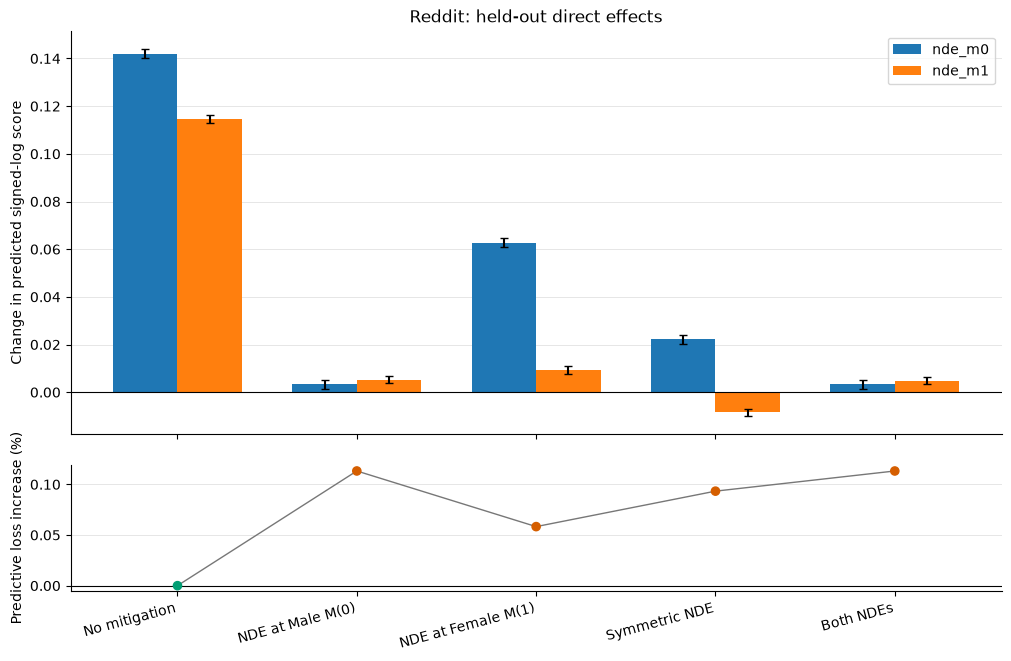

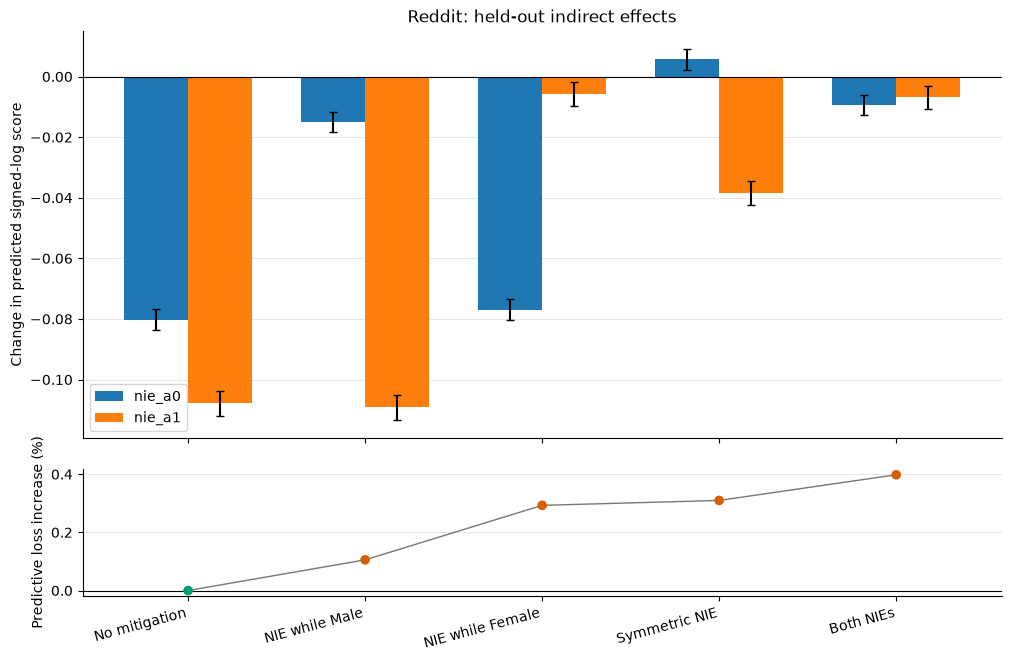

In [16]:
reddit_direct_effects = effect_results_frame(reddit_result['direct'], ('nde_m0', 'nde_m1'))
reddit_indirect_effects = effect_results_frame(reddit_result['indirect'], ('nie_a0', 'nie_a1'))
display(reddit_direct_effects.round(4))
display(reddit_indirect_effects.round(4))

plot_strategy_effects(
    reddit_result['direct'], ('nde_m0', 'nde_m1'),
    reddit_result['performance'], metric='rmse',
    title='Reddit: held-out direct effects',
    ylabel='Change in predicted signed-log score',
)
plt.show()
plot_strategy_effects(
    reddit_result['indirect'], ('nie_a0', 'nie_a1'),
    reddit_result['performance'], metric='rmse',
    title='Reddit: held-out indirect effects',
    ylabel='Change in predicted signed-log score',
)
plt.show()

In [17]:
display(reddit_result['performance'].set_index(['strategy', 'scope']).round(4))
display(overlap_summary(reddit_result['held_out_evaluations']).set_index('strategy').round(4))
reddit_optimization = pd.DataFrame({
    strategy: fitted['optimization']
    for strategy, fitted in reddit_result['models'].items()
}).T
display(reddit_optimization[['converged', 'prediction_loss', 'objective', 'message']])

n    rmse     mae      r2
strategy           scope                                  
No mitigation      overall  130840  1.1688  0.8682  0.0924
                   A=0       58133  1.2807  0.9500  0.0637
                   A=1       72707  1.0709  0.8028  0.1229
NDE at Male M(0)   overall  130840  1.1701  0.8696  0.0903
                   A=0       58133  1.2822  0.9596  0.0615
                   A=1       72707  1.0721  0.7977  0.1209
NDE at Female M(1) overall  130840  1.1695  0.8694  0.0913
                   A=0       58133  1.2818  0.9580  0.0622
                   A=1       72707  1.0713  0.7985  0.1223
Symmetric NDE      overall  130840  1.1699  0.8697  0.0907
                   A=0       58133  1.2822  0.9600  0.0616
                   A=1       72707  1.0717  0.7975  0.1217
Both NDEs          overall  130840  1.1701  0.8696  0.0903
                   A=0       58133  1.2822  0.9596  0.0615
                   A=1       72707  1.0721  0.7977  0.1210
NIE while Male     overall  130840  1.1700  0.8701  0.0905
                   A=0       58133  1.2832  0.9543  0.0600
                   A=1       72707  1.0709  0.8028  0.1229
NIE while Female   overall  130840  1.1722  0.8718  0.0871
                   A=0       58133  1.2807  0.9500  0.0637
                   A=1       72707  1.0776  0.8092  0.1119
Symmetric NIE      overall  130840  1.1724  0.8728  0.0867
                   A=0       58133  1.2849  0.9563  0.0576
                   A=1       72707  1.0740  0.8060  0.1178
Both NIEs          overall  130840  1.1734  0.8737  0.0851
                   A=0       58133  1.2832  0.9543  0.0600
                   A=1       72707  1.0776  0.8092  0.1119

,max_propensity_c_clipped,max_propensity_mc_clipped,max_absolute_weight,effective_sample_size
strategy,,,,
No mitigation,0.0,0.0,36.3762,34436.66
NDE at Male M(0),0.0,0.0,36.3762,34436.66
NDE at Female M(1),0.0,0.0,36.3762,34436.66
Symmetric NDE,0.0,0.0,36.3762,34436.66
Both NDEs,0.0,0.0,36.3762,34436.66
NIE while Male,0.0,0.0,36.3762,34436.66
NIE while Female,0.0,0.0,36.3762,34436.66
Symmetric NIE,0.0,0.0,36.3762,34436.66
Both NIEs,0.0,0.0,36.3762,34436.66


,converged,prediction_loss,objective,message
No mitigation,True,1.375348,1.37535,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NDE at Male M(0),True,1.379138,1.379214,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NDE at Female M(1),True,1.377541,1.377582,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NDE,True,1.378634,1.378706,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
Both NDEs,True,1.379139,1.379214,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while Male,True,1.378896,1.379158,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
NIE while Female,True,1.384201,1.385052,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Symmetric NIE,True,1.385243,1.386892,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
Both NIEs,True,1.387749,1.38886,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## Four-dataset mitigation summary

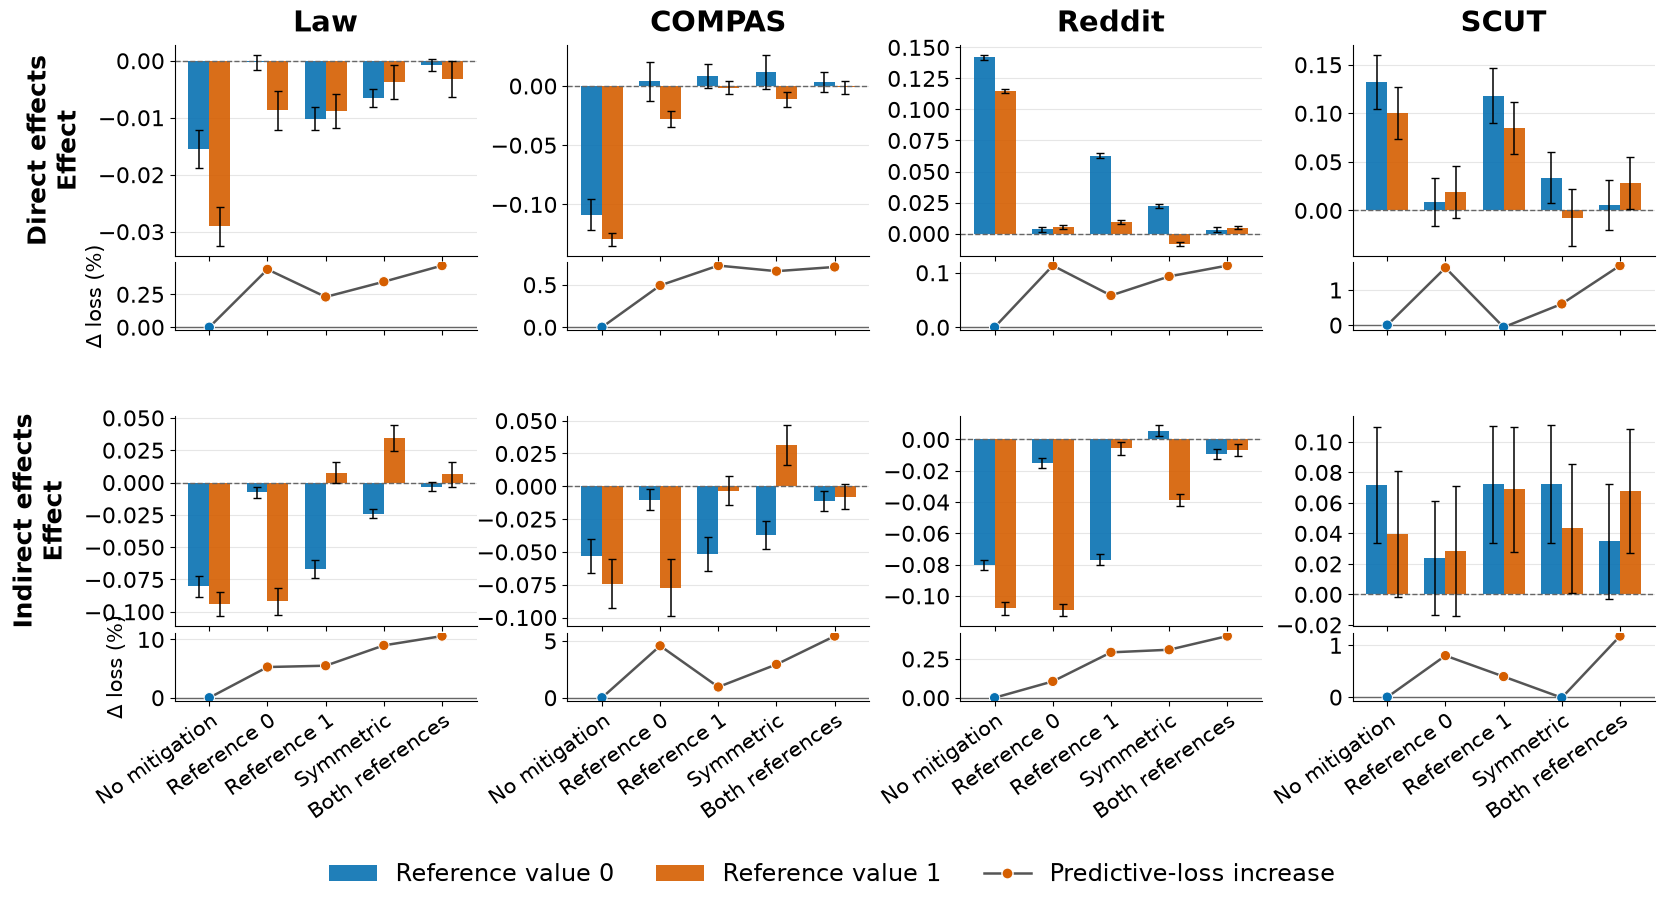

In [18]:
mitigation_results = {
    'Law': law_result,
    'COMPAS': compas_result,
    'Reddit': reddit_result,
    'SCUT': scut_result,
}

fig = plot_mitigation_summary_figure(mitigation_results)
plt.show()


In [19]:
overview_table = mitigation_compact_overview_table(mitigation_results)

display(
    overview_table.style
    .format({
        'Reference 0': '{:.3f}',
        'Reference 1': '{:.3f}',
        'Symmetric effect': '{:.3f}',
        'Predictive loss': '{:.3f}',
        'Loss increase (%)': '{:+.1f}%',
    })
    .background_gradient(
        subset=['Loss increase (%)'],
        cmap='Oranges',
        vmin=0,
    )
    .hide(axis='index')
)


Dataset,Pathway,Strategy,Reference 0,Reference 1,Symmetric effect,95% CI,Loss metric,Predictive loss,Loss increase (%)
Law,Direct,No mitigation,-0.015,-0.029,-0.022,"[-0.025, -0.020]",log_loss,0.152,+0.0%
Law,Direct,Symmetric NDE,-0.007,-0.004,-0.005,"[-0.007, -0.003]",log_loss,0.152,+0.3%
Law,Direct,Both NDEs,-0.001,-0.003,-0.002,"[-0.004, -0.000]",log_loss,0.152,+0.5%
Law,Indirect,No mitigation,-0.080,-0.094,-0.087,"[-0.096, -0.078]",log_loss,0.152,+0.0%
Law,Indirect,Symmetric NIE,-0.024,0.034,0.005,"[-0.000, 0.011]",log_loss,0.165,+9.0%
Law,Indirect,Both NIEs,-0.003,0.006,0.002,"[-0.004, 0.007]",log_loss,0.168,+10.6%
COMPAS,Direct,No mitigation,-0.109,-0.130,-0.119,"[-0.127, -0.111]",log_loss,0.615,+0.0%
COMPAS,Direct,Symmetric NDE,0.012,-0.011,0.000,"[-0.009, 0.009]",log_loss,0.619,+0.7%
COMPAS,Direct,Both NDEs,0.004,-0.001,0.001,"[-0.005, 0.007]",log_loss,0.620,+0.7%
COMPAS,Indirect,No mitigation,-0.053,-0.074,-0.064,"[-0.078, -0.049]",log_loss,0.615,+0.0%


In [20]:
overview_table = mitigation_overview_table(mitigation_results, decimals=3)

display(
    overview_table.style
    .format({
        'Reference 0': '{:.3f}',
        'Reference 1': '{:.3f}',
        'Symmetric effect': '{:.3f}',
        'Predictive loss': '{:.3f}',
        'Loss increase (%)': '{:+.1f}%',
        'Secondary performance': '{:.3f}',
        'Secondary change': '{:+.3f}',
    })
    .background_gradient(
        subset=['Loss increase (%)'],
        cmap='Oranges',
        vmin=0,
    )
    .hide(axis='index')
)


Dataset,Pathway,Strategy,Reference 0,Reference 0 95% CI,Reference 1,Reference 1 95% CI,Symmetric effect,Symmetric effect 95% CI,Loss metric,Predictive loss,Loss increase (%),Secondary metric,Secondary performance,Secondary change
Law,Direct,No mitigation,-0.015,"[-0.019, -0.012]",-0.029,"[-0.033, -0.026]",-0.022,"[-0.025, -0.020]",Log loss,0.152,+0.0%,AUROC,0.860,+0.000
Law,Direct,NDE M(0),-0.000,"[-0.002, 0.001]",-0.009,"[-0.012, -0.005]",-0.004,"[-0.006, -0.002]",Log loss,0.152,+0.4%,AUROC,0.859,-0.001
Law,Direct,NDE M(1),-0.010,"[-0.012, -0.008]",-0.009,"[-0.012, -0.006]",-0.010,"[-0.011, -0.008]",Log loss,0.152,+0.2%,AUROC,0.859,-0.001
Law,Direct,Symmetric NDE,-0.007,"[-0.008, -0.005]",-0.004,"[-0.007, -0.001]",-0.005,"[-0.007, -0.003]",Log loss,0.152,+0.3%,AUROC,0.859,-0.001
Law,Direct,Both NDEs,-0.001,"[-0.002, 0.000]",-0.003,"[-0.006, -0.000]",-0.002,"[-0.004, -0.000]",Log loss,0.152,+0.5%,AUROC,0.859,-0.001
Law,Indirect,No mitigation,-0.080,"[-0.089, -0.072]",-0.094,"[-0.104, -0.084]",-0.087,"[-0.096, -0.078]",Log loss,0.152,+0.0%,AUROC,0.860,+0.000
Law,Indirect,NIE A=0,-0.008,"[-0.012, -0.004]",-0.092,"[-0.102, -0.081]",-0.050,"[-0.056, -0.043]",Log loss,0.160,+5.3%,AUROC,0.827,-0.033
Law,Indirect,NIE A=1,-0.067,"[-0.074, -0.060]",0.008,"[-0.000, 0.016]",-0.030,"[-0.036, -0.024]",Log loss,0.160,+5.5%,AUROC,0.838,-0.022
Law,Indirect,Symmetric NIE,-0.024,"[-0.028, -0.020]",0.034,"[0.024, 0.044]",0.005,"[-0.000, 0.011]",Log loss,0.165,+9.0%,AUROC,0.822,-0.038
Law,Indirect,Both NIEs,-0.003,"[-0.006, 0.000]",0.006,"[-0.003, 0.016]",0.002,"[-0.004, 0.007]",Log loss,0.168,+10.6%,AUROC,0.806,-0.054
